# TV4 – Công việc 1.6: Phân tích gen khác biệt (H1)

**Thành viên:** Trần Ngọc Nam (TV4)
**Thời gian:** Tuần 3–4 · Bàn giao: Chủ nhật 01/11

## 1. Giả thuyết H1

> Có nhiều gen tương quan với sự phân biệt ALL/AML hơn mức ngẫu nhiên.

**Giải thích dễ hiểu:** Trong khoảng 7000 gen đo được, nếu ALL và AML thực sự là hai bệnh khác nhau ở mức phân tử, thì sẽ có **rất nhiều** gen có mức biểu hiện khác biệt rõ giữa hai nhóm bệnh nhân. Số gen khác biệt đó phải **lớn hơn hẳn** số gen trông như khác biệt chỉ do tình cờ, khi ta chia bệnh nhân thành hai nhóm một cách ngẫu nhiên.

Nói cách khác, H1 không hỏi "gen nào gây bệnh" mà hỏi: *sự khác biệt giữa ALL và AML có được phản ánh rộng rãi và có thật trong dữ liệu biểu hiện gen hay không?* Nếu có, việc dùng gen để phân loại hai bệnh này (giai đoạn 2) là có cơ sở.

## 2. Định nghĩa

- **ALL** (Acute Lymphoblastic Leukemia, bạch cầu cấp dòng lympho): ung thư máu bắt nguồn từ tế bào tiền thân của dòng lympho (tế bào B hoặc T). Trong dữ liệu: 47 bệnh nhân (38 B-ALL, 9 T-ALL).
- **AML** (Acute Myeloid Leukemia, bạch cầu cấp dòng tủy): ung thư máu bắt nguồn từ tế bào tiền thân của dòng tủy (bạch cầu hạt, bạch cầu đơn nhân…). Trong dữ liệu: 25 bệnh nhân.
  - Hai bệnh có biểu hiện lâm sàng giống nhau nhưng phác đồ điều trị khác nhau, nên phân biệt đúng là rất quan trọng. Năm 1999, việc này phải dựa vào nhiều xét nghiệm và kinh nghiệm của bác sĩ.
- **Gen khác biệt (differentially expressed gene):** gen có mức biểu hiện trung bình khác nhau rõ rệt giữa nhóm ALL và nhóm AML, đo bằng:
  - **SNR** (signal-to-noise ratio) của Golub: P(g) = (μ_ALL − μ_AML) / (σ_ALL + σ_AML). |P| càng lớn thì gen càng phân biệt tốt; dấu của P cho biết gen cao hơn ở nhóm nào.
  - **Welch t-test:** kiểm định hai trung bình có khác nhau không, cho ra p-value.
- **Mức ngẫu nhiên:** số gen trông như khác biệt **khi nhãn ALL/AML không có ý nghĩa**. Cách đo: xáo trộn ngẫu nhiên nhãn của 38 bệnh nhân (giữ nguyên 27 ALL và 11 AML), tính lại SNR, đếm số gen vượt ngưỡng; lặp lại khoảng 400 lần. Kết quả cho một phân bố "số gen khác biệt do tình cờ". Ngưỡng 1% và 5% là giá trị mà chỉ 1% và 5% số lần xáo trộn vượt qua. Phương pháp này gọi là **neighborhood analysis** (Golub et al., 1999).
- **Đa kiểm định và FDR:** khi kiểm định hàng nghìn gen cùng lúc, nếu dùng ngưỡng p < 0,05 thì riêng do tình cờ đã có khoảng 5% số gen bị coi là khác biệt (khoảng 177 trên 3541 gen). Hiệu chỉnh **Benjamini–Hochberg** chuyển p-value thành **q-value**: giữ các gen có q < 0,05 nghĩa là kỳ vọng không quá 5% số gen được chọn là phát hiện sai.

## 3. Cách kiểm chứng H1

| Cách | Câu hỏi trả lời | Kết luận ủng hộ H1 khi |
|---|---|---|
| Neighborhood analysis (hình F6) | Số gen có \|SNR\| vượt ngưỡng ở nhãn thật có lớn hơn khi xáo nhãn không? | Đường nhãn thật nằm trên dải 1% của nhãn hoán vị |
| Welch t-test + Benjamini–Hochberg | Bao nhiêu gen khác biệt có ý nghĩa sau khi kiểm soát phát hiện sai? | Số gen có q < 0,05 lớn |
| Volcano plot | Gen khác biệt phân bố thế nào theo độ lớn và độ tin cậy? | Có nhiều gen vừa chênh lệch lớn vừa p nhỏ |

Kiểm tra bổ trợ: histogram SNR (6.5), box plot top gen (6.7), PCA toàn bộ gen (6.8), hạn chế và độ vững — St-Jude, bỏ mẫu 21 (6.9), so với 50 gen của Golub (6.10).

Mốc so sánh từ bài báo: khoảng **1100 gen** tương quan với phân biệt ALL/AML vượt mức ngẫu nhiên ở mức ý nghĩa 1% (trên 6817 gen).

## 4. Đầu vào

| Dữ liệu | Nguồn | Ghi chú |
|---|---|---|
| `data/curated/X_log10_filtered.parquet` | TV3 (1.2) | 72 × 3571; đã threshold [100, 16000] + log10 + lọc Dudoit. Dùng được cho phân tích khám phá |
| `data/curated/samples.parquet` | TV2 / TV3 | Nhãn `class`, `split`, cờ `qc_outlier` |
| `data/standardized/genes.parquet` | TV2 (1.1) | `description`, `is_control` để bỏ probe AFFX và gộp theo gen |

Xử lý trước khi phân tích:
- Chỉ dùng **38 mẫu train** (27 ALL, 11 AML); tập test giữ nguyên để đánh giá ở giai đoạn 2.
- Bỏ **22 probe điều khiển AFFX** còn sót sau bộ lọc → 3549 gen; bỏ tiếp **8 gen hằng số** trên 38 mẫu train (xem 6.2) → còn **3541 gen**.
- Lưu ý thiết kế: trong tập train, mọi ALL đến từ DFCI và mọi AML từ CALGB, nên một phần khác biệt có thể do khác nơi lấy mẫu (batch effect).

## 5. Đầu ra

- `results/gene_lists/gene_ranking.csv`: các cột `probe_id, description, snr, t_stat, p_value, q_value, rank`. Dùng cho 2.1 (TV1), 2.2 (TV4), 2.5 (TV5).
- `results/gene_lists/golub50_comparison.csv`: đối chiếu với 50 gen của Golub.
- Hình trong `results/figures/report/`: **F6** (neighborhood analysis), F6b, F6c, **volcano**, box plot top gen, PCA, kiểm tra St-Jude.
- Số gen trùng giữa top 50 của nhóm và 50 gen của Golub.
- Kết luận H1 và ghi chú bàn giao `docs/handover/1.6.md`.

## 6. Luồng xử lý

### 6.1 Nạp và preview dữ liệu 

Nạp đầu vào và kiểm tra trực quan

In [1]:
from pathlib import Path
import sys

# Chạy từ notebooks/ nên phải đưa gốc repo (chứa src/, data/, results/) vào sys.path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import CURATED_DIR, STD_DIR, PALETTE, RANDOM_SEED
from src.load import load_golub

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

# --- Nạp đầu vào (đường dẫn lấy từ src.config nên chạy được từ notebooks/ hay gốc repo) ---
X_all = pd.read_parquet(CURATED_DIR / "X_log10_filtered.parquet")
_, samples = load_golub("curated")
genes = pd.read_parquet(STD_DIR / "genes.parquet").set_index("probe_id")
X_all.index = X_all.index.astype(int)

# --- Bỏ probe điều khiển AFFX, chỉ giữ 38 mẫu train ---
is_ctrl = genes.loc[X_all.columns, "is_control"].to_numpy()
X = X_all.loc[:, ~is_ctrl]
tr = samples["split"] == "train"
Xtr, ytr = X.loc[tr], samples.loc[tr, "class"]

print(f"X_log10_filtered : {X_all.shape}  (bỏ {is_ctrl.sum()} probe AFFX -> {X.shape[1]} gen)")
print(f"Train            : {Xtr.shape}  {ytr.value_counts().to_dict()}")

# --- Kiểm tra: dừng ngay nếu đầu vào không như kỳ vọng ---
checks = {
    "X và samples cùng chỉ mục sample_id": X_all.index.equals(samples.index),
    "72 mẫu, 3571 probe trước khi bỏ AFFX": X_all.shape == (72, 3571),
    "đúng 22 probe AFFX bị bỏ": int(is_ctrl.sum()) == 22,
    "không có giá trị thiếu": not X.isna().any().any(),
    "giá trị trong [2.0, 4.204] (log10 sau threshold)":
        X.min().min() >= 2.0 and X.max().max() <= np.log10(16000) + 1e-9,
    "train = 27 ALL + 11 AML": ytr.value_counts().to_dict() == {"ALL": 27, "AML": 11},
    "train toàn bộ là mẫu 1..38": list(Xtr.index) == list(range(1, 39)),
    "không còn probe AFFX": not X.columns.str.startswith("AFFX").any(),
}
for name, ok in checks.items():
    print(f"[{'PASS' if ok else 'FAIL'}] {name}")
assert all(checks.values()), "Đầu vào không đạt — chạy lại `python run_all.py data`"


X_log10_filtered : (72, 3571)  (bỏ 22 probe AFFX -> 3549 gen)
Train            : (38, 3549)  {'ALL': 27, 'AML': 11}
[PASS] X và samples cùng chỉ mục sample_id
[PASS] 72 mẫu, 3571 probe trước khi bỏ AFFX
[PASS] đúng 22 probe AFFX bị bỏ
[PASS] không có giá trị thiếu
[PASS] giá trị trong [2.0, 4.204] (log10 sau threshold)
[PASS] train = 27 ALL + 11 AML
[PASS] train toàn bộ là mẫu 1..38
[PASS] không còn probe AFFX


In [2]:
# Bảng mẫu của tập train: lớp × nguồn (nhắc lại vấn đề batch effect)
print(pd.crosstab([samples.loc[tr, "class"], samples.loc[tr, "subtype"]],
                  samples.loc[tr, "source"], margins=True, margins_name="Tổng"))

print(Xtr.iloc[:5, :6].round(3))

# Hai gen đã biết từ bài báo: Zyxin và CD33 (đều cao ở AML)
known = {"X95735_at": "Zyxin", "M23197_at": "CD33"}
print(Xtr[list(known)].rename(columns=known).groupby(ytr).agg(["mean", "std"]).round(3))

source         CALGB  DFCI  Tổng
class subtype                   
ALL   B-ALL        0    19    19
      T-ALL        0     8     8
AML   AML         11     0    11
Tổng              11    27    38
           A28102_at  AB000115_at  AB000409_at  AB000449_at  AB000464_at  AB000468_at
sample_id                                                                            
1              2.179        2.449        2.000        2.000        2.905        2.577
2              2.420        2.398        2.000        2.228        2.879        2.396
3              2.000        2.554        2.152        2.555        3.400        2.559
4              2.685        2.072        2.000        2.438        3.173        2.425
5              2.072        2.294        2.375        2.493        2.508        2.744
       Zyxin          CD33       
        mean    std   mean    std
class                            
ALL    2.494  0.362  2.214  0.180
AML    3.430  0.224  2.823  0.251


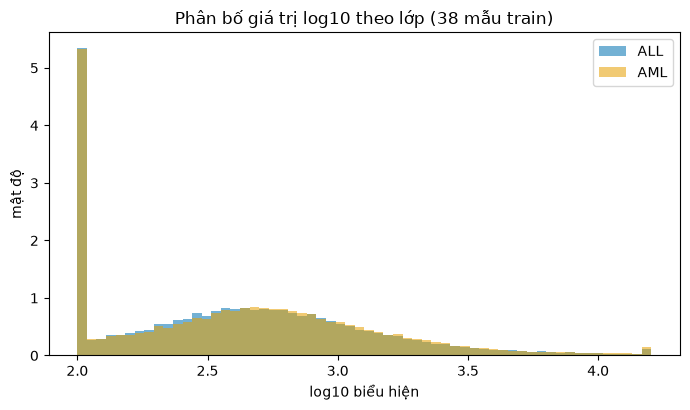

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.2))

# (a) Phân bố giá trị log10 theo lớp
for cls in ["ALL", "AML"]:
    ax.hist(Xtr.loc[ytr == cls].to_numpy().ravel(), bins=60, alpha=0.55,
            density=True, color=PALETTE[cls], label=cls)
ax.set(title="Phân bố giá trị log10 theo lớp (38 mẫu train)",
       xlabel="log10 biểu hiện", ylabel="mật độ")
ax.legend()

fig.tight_layout()
plt.show()


### 6.2 Hàm dùng chung

Các hàm tính toán dùng lại ở mọi mục sau. Tất cả đều **vector hóa** (tính một lần cho cả 3541 gen, không lặp từng gen) vì ở 6.4 phải gọi lại 400 lần.

| Hàm | Công thức | Trả về | Dùng ở |
|---|---|---|---|
| `snr(X, is_all)` | $P(g) = \dfrac{\mu_{ALL} - \mu_{AML}}{\sigma_{ALL} + \sigma_{AML}}$ (Golub et al., 1999) | SNR từng gen; > 0: cao ở ALL, < 0: cao ở AML | 6.3, 6.4, xếp hạng gen |
| `pearson_r(X, is_all)` | Hệ số Pearson giữa gen và vector nhãn (ALL = 1, AML = 0) — Bài 4 | r ∈ [−1, 1] | 6.3 (kiểm tra chéo SNR) |
| `welch(X, is_all)` | $t = \dfrac{\mu_{ALL} - \mu_{AML}}{\sqrt{\sigma^2_{ALL}/n_{ALL} + \sigma^2_{AML}/n_{AML}}}$, p tra phân phối t (bậc tự do Welch–Satterthwaite) | (t, p) từng gen | 6.3, 6.6 |
| `count_above(scores, thresholds)` | Đếm số gen có \|score\| > từng ngưỡng | số gen theo ngưỡng | 6.4 |

- **SNR** đo hai nhóm *tách nhau* rõ đến đâu (không phụ thuộc số mẫu) → dùng để xếp hạng gen như bài báo.
- **Welch t-test** đo khác biệt trung bình *có thật* không và cho p-value; dùng Welch vì hai nhóm khác cỡ mẫu (27/11) và khác phương sai.
- `is_all` là nhãn dạng True/False (27 ALL, 11 AML), truyền vào như tham số để ở 6.4 có thể thay bằng nhãn **đã xáo trộn**.

**Bỏ gen hằng số:** 8 gen có giá trị bằng 2.0 (mức sàn) ở cả 38 mẫu train (chúng chỉ thay đổi ở tập test nên vẫn qua bộ lọc 72 mẫu). Với các gen này σ = 0 → SNR và p = NaN, và chỉ một p NaN cũng làm hiệu chỉnh Benjamini–Hochberg trả NaN cho **toàn bộ** q-value. Vì vậy bỏ chúng trước khi tính.

In [4]:
from scipy import stats as st
from statsmodels.stats.multitest import multipletests


def snr(X: np.ndarray, is_all: np.ndarray) -> np.ndarray:
    """SNR của Golub cho mọi gen: (μ_ALL − μ_AML) / (σ_ALL + σ_AML).
    X: (n_mẫu, n_gen); is_all: bool (n_mẫu,). Trả về (n_gen,). >0: cao ở ALL, <0: cao ở AML."""
    a, b = X[is_all], X[~is_all]                     # tách hai nhóm theo hàng
    return (a.mean(axis=0) - b.mean(axis=0)) / (a.std(axis=0, ddof=1) + b.std(axis=0, ddof=1))

def pearson_r(X: np.ndarray, is_all: np.ndarray) -> np.ndarray:
    """Hệ số Pearson giữa từng gen và vector nhãn (ALL=1, AML=0) — Bài 4."""
    y = is_all.astype(float) - is_all.mean()          # nhãn đã trừ trung bình
    Xc = X - X.mean(axis=0)                           # mỗi gen trừ trung bình của nó
    return (Xc * y[:, None]).sum(axis=0) / np.sqrt((Xc ** 2).sum(axis=0) * (y ** 2).sum())

def welch(X: np.ndarray, is_all: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Welch t-test từng gen (không giả định hai nhóm cùng phương sai). Trả về (t, p)."""
    t, p = st.ttest_ind(X[is_all], X[~is_all], equal_var=False, axis=0)
    return t, p


def count_above(scores: np.ndarray, thresholds: np.ndarray) -> np.ndarray:
    """Số gen có |score| > từng ngưỡng. Trả về (len(thresholds),)."""
    return np.sum(np.abs(scores[:, None]) > thresholds[None, :], axis=0)


# --- Bỏ gen hằng số trên 38 mẫu train ---
# Các gen này ở mức sàn 2.0 với mọi mẫu train (chỉ thay đổi ở tập test nên vẫn qua bộ lọc 72 mẫu).
# σ = 0 -> SNR, p = NaN; chỉ một p NaN cũng làm multipletests trả NaN cho TOÀN BỘ q-value.
const = Xtr.std() == 0
print(f"Bỏ {const.sum()} gen hằng số trên train -> còn {(~const).sum()} gen")
Xtr = Xtr.loc[:, ~const]
X = X.loc[:, Xtr.columns]            # giữ X (72 mẫu) đồng bộ cột với Xtr

# --- Biến dùng chung cho các mục sau ---
Xtr_np = Xtr.to_numpy()
is_all = (ytr == "ALL").to_numpy()
rng = np.random.default_rng(RANDOM_SEED)

# --- Kiểm tra nhanh ---
s = snr(Xtr_np, is_all)
assert not np.isnan(s).any(), "còn gen cho SNR = NaN"
j = Xtr.columns.get_loc("X95735_at")
print(f"Kiểm tra Zyxin: SNR = {s[j]:.3f} (kỳ vọng ≈ -1.597), r = {pearson_r(Xtr_np, is_all)[j]:.3f} (≈ -0.798)")


Bỏ 8 gen hằng số trên train -> còn 3541 gen
Kiểm tra Zyxin: SNR = -1.597 (kỳ vọng ≈ -1.597), r = -0.798 (≈ -0.798)


**Kết quả:** bỏ 8 gen hằng số → còn **3541 gen**. Kiểm tra với Zyxin: SNR = −1,597, r = −0,798, khớp với tính tay và `scipy.stats.pearsonr`.


### 6.3 Chỉ số khác biệt của từng gen

Tính cho 3541 gen trên **38 mẫu train**: trung bình mỗi lớp, `log_fc`, SNR, Pearson r, Welch t, p-value và **q-value** (hiệu chỉnh Benjamini–Hochberg).

**Vì sao cần q-value:** kiểm định 3541 gen cùng lúc thì riêng do tình cờ đã có ≈ 5% × 3541 ≈ 177 gen đạt p < 0,05. Benjamini–Hochberg (xếp p tăng dần, tính p × m / k rồi làm đơn điệu) cho q: chọn các gen có **q < 0,05** thì kỳ vọng **không quá 5% số gen được chọn là phát hiện sai**.

Các cột của bảng `stats`:

| Cột | Ý nghĩa |
|---|---|
| `mean_all`, `mean_aml` | trung bình log10 trong mỗi lớp |
| `log_fc` | `mean_aml − mean_all`; > 0: cao ở AML; 1 đơn vị = gấp 10 lần |
| `snr`, `pearson_r` | mức phân biệt; > 0: cao ở ALL |
| `t_stat`, `p_value`, `q_value` | Welch t-test và Benjamini–Hochberg |
| `higher_in` | gen cao hơn ở lớp nào |
| `rank` | thứ hạng theo \|SNR\| giảm dần (1 = phân biệt tốt nhất), giống cách Golub chọn gen |


In [5]:
# --- Tính chỉ số cho mọi gen trên 38 mẫu train ---
snr_v = snr(Xtr_np, is_all)
r_v = pearson_r(Xtr_np, is_all)
t_v, p_v = welch(Xtr_np, is_all)
q_v = multipletests(p_v, method="fdr_bh")[1]          # hiệu chỉnh Benjamini–Hochberg

mean_all = Xtr_np[is_all].mean(axis=0)
mean_aml = Xtr_np[~is_all].mean(axis=0)

stats = pd.DataFrame({
    "probe_id": Xtr.columns,
    "description": genes.loc[Xtr.columns, "description"].to_numpy(),
    "mean_all": mean_all,
    "mean_aml": mean_aml,
    "log_fc": mean_aml - mean_all,                    # >0: cao ở AML (thang log10; 1 = gấp 10 lần)
    "snr": snr_v,
    "pearson_r": r_v,
    "t_stat": t_v,
    "p_value": p_v,
    "q_value": q_v,
})
stats["higher_in"] = np.where(stats["snr"] > 0, "ALL", "AML")

# Xếp hạng theo |SNR| giảm dần (giống cách Golub chọn gen); rank 1 = phân biệt tốt nhất
stats = stats.sort_values("snr", key=np.abs, ascending=False, ignore_index=True)
stats["rank"] = np.arange(1, len(stats) + 1)

# --- Kiểm tra ---
assert not stats[["snr", "t_stat", "p_value", "q_value"]].isna().any().any(), "còn NaN"
assert np.array_equal(np.sign(stats["snr"]), np.sign(stats["t_stat"])), "SNR và t ngược dấu"

print(f"Số gen: {len(stats)}  |  cao ở ALL: {(stats['higher_in'] == 'ALL').sum()}"
      f"  |  cao ở AML: {(stats['higher_in'] == 'AML').sum()}")
print(f"Số gen p < 0.05: {(stats['p_value'] < 0.05).sum()}  |  q < 0.05: {(stats['q_value'] < 0.05).sum()}"
      f"  |  q < 0.01: {(stats['q_value'] < 0.01).sum()}")

known = {"X95735_at": "Zyxin", "M23197_at": "CD33"}
print("\nGen đã biết:")
print(stats.loc[stats["probe_id"].isin(known), ["rank", "probe_id", "snr", "log_fc", "q_value", "higher_in"]]
      .assign(gene=lambda d: d["probe_id"].map(known)).round(4).to_string(index=False))

# --- Xem trước: top 10 mỗi phía ---
show = ["rank", "probe_id", "description", "snr", "log_fc", "q_value"]
for side in ["ALL", "AML"]:
    top = stats.loc[stats["higher_in"] == side, show].head(10).copy()
    top["description"] = top["description"].str.slice(0, 45)
    print(f"\nTop 10 gen cao ở {side}:")
    print(top.round(4).to_string(index=False))


Số gen: 3541  |  cao ở ALL: 1598  |  cao ở AML: 1943
Số gen p < 0.05: 1110  |  q < 0.05: 627  |  q < 0.01: 265

Gen đã biết:
 rank  probe_id     snr  log_fc  q_value higher_in  gene
    2 X95735_at -1.5967  0.9363   0.0000       AML Zyxin
    4 M23197_at -1.4127  0.6087   0.0002       AML  CD33

Top 10 gen cao ở ALL:
 rank         probe_id                                   description    snr  log_fc  q_value
    6 U22376_cds2_s_at C-myb gene extracted from Human (c-myb) gene; 1.3719 -0.7323   0.0001
   11        M31523_at TCF3 Transcription factor 3 (E2A immunoglobul 1.2531 -0.5870   0.0000
   13        X74262_at            RETINOBLASTOMA BINDING PROTEIN P48 1.2064 -0.6814   0.0001
   19        M89957_at      IGB Immunoglobulin-associated beta (B29) 1.1762 -0.7562   0.0002
   20        X15949_at           IRF2 Interferon regulatory factor 2 1.1673 -0.3786   0.0002
   21        L47738_at                        Inducible protein mRNA 1.1655 -0.7194   0.0001
   24   X82240_rna1_at TCL1 ge

D:\Project\University\IT5424_QTDL-va-TQH\Golub-project\.venv\Lib\site-packages\scipy\stats\_axis_nan_policy.py:644: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, axis=axis, **kwds)


**Kết quả:**
- 3541 gen: 1598 gen cao ở ALL, 1943 gen cao ở AML.
- **p < 0,05: 1110 gen** (chưa hiệu chỉnh) → **q < 0,05: 627 gen** → q < 0,01: 265 gen. Hiệu chỉnh FDR loại bớt gần một nửa, nhưng vẫn còn rất nhiều gen khác biệt có ý nghĩa.
- Hai gen đã biết từ bài báo nằm ở đầu bảng: **Zyxin** (rank 2, SNR = −1,60) và **CD33** (rank 4, SNR = −1,41), đều cao ở AML.
- Top gen trùng nhiều với danh sách của Golub: phía AML có CST3, Zyxin, LTC4S, CD33, adipsin, LEPR…; phía ALL có c-myb, TCF3 (E2A), CD19, IGB, TCL1…

**Gen cao ở AML chiếm ưu thế ở đầu bảng** (9/10 trong top 10, 32/50 trong top 50) vì nhóm ALL không đồng nhất: gồm 19 B-ALL và 8 T-ALL. Nhiều gen đặc trưng B-ALL (IGB, TCL1, CD19) thấp ở T-ALL, làm σ_ALL tăng và SNR giảm. Khi chỉ so B-ALL với AML, top 50 cân bằng (27/23). Vì vậy khi chọn gen nên lấy **25 gen mỗi phía** như Golub, không lấy top 50 chung.


### 6.4 Neighborhood analysis (hình F6) — bằng chứng chính cho H1

**Câu hỏi:** số gen phân biệt ALL/AML có nhiều hơn mức có thể xảy ra do tình cờ không?

**Ý tưởng:** nếu nhãn ALL/AML không liên quan đến gen, thì gán nhãn ngẫu nhiên cũng cho số gen "khác biệt" tương đương. Ta so nhãn thật với nhãn ngẫu nhiên.

**Cách làm** (Golub et al., 1999):
1. Với nhãn thật, đếm số gen có |SNR| > ngưỡng, cho dãy ngưỡng từ 0 đến 1,8.
2. Xáo trộn nhãn của 38 mẫu (giữ nguyên 27 ALL / 11 AML), tính lại SNR và đếm lại. Lặp **400 lần**.
3. Tại mỗi ngưỡng, lấy phân vị 95% và 99% của 400 lần làm **dải 5%** và **dải 1%**: chỉ 5% (1%) số lần xáo nhãn cho nhiều gen hơn mức này.
4. **p thực nghiệm** = tỷ lệ số lần xáo nhãn cho số gen ≥ nhãn thật.

Đếm theo 3 cách: |SNR| (cả hai phía), chỉ gen cao ở ALL, chỉ gen cao ở AML (giống Figure 2 của bài báo).

**Ủng hộ H1 khi:** đường nhãn thật nằm trên dải 1%.


|SNR| (cả hai phía) : tại ngưỡng 0.34 có 1301 gen, dải 1% = 765 -> vượt mức ngẫu nhiên ≈ 536 gen
cao ở ALL           : tại ngưỡng 0.52 có 309 gen, dải 1% = 132 -> vượt mức ngẫu nhiên ≈ 177 gen
cao ở AML           : tại ngưỡng 0.50 có 351 gen, dải 1% = 142 -> vượt mức ngẫu nhiên ≈ 209 gen

 ngưỡng |SNR|  nhãn thật  trung vị hoán vị  dải 5%  dải 1%  thật / dải 1%  p thực nghiệm
          0.3       1503             389.0  818.05 1001.11            1.5            0.0
          0.5        685              29.0  131.05  209.22            3.3            0.0
          0.8        161               0.0    3.00    6.00           26.8            0.0
          1.0         55               0.0    0.05    1.00           55.0            0.0
          1.2         14               0.0    0.00    0.00           14.0            0.0

Số lần hoán vị cho số gen ≥ nhãn thật tại ngưỡng 0.5: 0/400


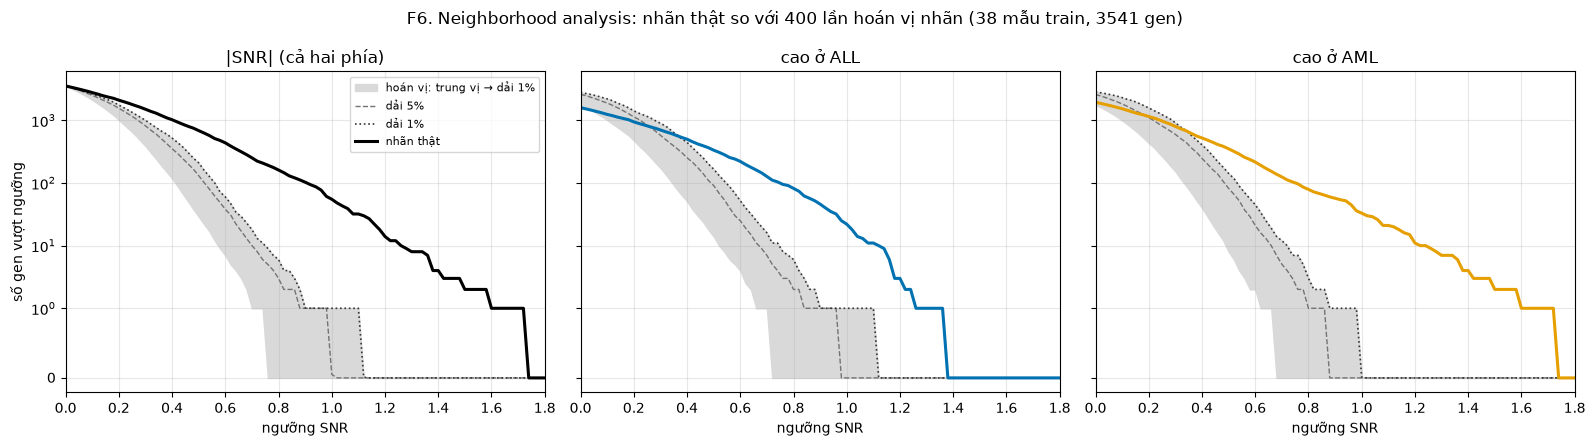

In [6]:
from src.config import REPORT_FIG_DIR

N_PERM = 400
thresholds = np.round(np.arange(0, 1.81, 0.02), 2)     # ngưỡng |SNR|

def side_counts(s: np.ndarray) -> np.ndarray:
    """Số gen vượt ngưỡng theo 3 cách đếm: (|SNR|, cao ở ALL: SNR>t, cao ở AML: SNR<−t). Trả về (3, n_ngưỡng)."""
    return np.vstack([count_above(s, thresholds),
                      (s[:, None] > thresholds).sum(axis=0),
                      (s[:, None] < -thresholds).sum(axis=0)])

# --- Nhãn thật ---
real = side_counts(stats.set_index("probe_id").loc[Xtr.columns, "snr"].to_numpy())

# --- 400 lần xáo nhãn (giữ nguyên 27 ALL / 11 AML) ---
perm = np.empty((N_PERM, 3, len(thresholds)))
for b in range(N_PERM):
    perm[b] = side_counts(snr(Xtr_np, rng.permutation(is_all)))

band_50, band_5, band_1 = np.percentile(perm, [50, 95, 99], axis=0)   # trung vị, dải 5%, dải 1%
p_emp = (perm >= real).mean(axis=0)                                    # p thực nghiệm tại từng ngưỡng

# --- Số gen "vượt mức ngẫu nhiên" (so với bài báo ~1100): chênh lớn nhất giữa nhãn thật và dải 1% ---
excess = real - band_1
best = excess.argmax(axis=1)
names = ["|SNR| (cả hai phía)", "cao ở ALL", "cao ở AML"]
for k, name in enumerate(names):
    i = best[k]
    print(f"{name:<20}: tại ngưỡng {thresholds[i]:.2f} có {real[k, i]:.0f} gen, dải 1% = {band_1[k, i]:.0f} "
          f"-> vượt mức ngẫu nhiên ≈ {excess[k, i]:.0f} gen")

# --- Bảng tại vài ngưỡng ---
pick = [np.where(np.isclose(thresholds, t))[0][0] for t in (0.3, 0.5, 0.8, 1.0, 1.2)]
table = pd.DataFrame({
    "ngưỡng |SNR|": thresholds[pick],
    "nhãn thật": real[0, pick].astype(int),
    "trung vị hoán vị": band_50[0, pick],
    "dải 5%": band_5[0, pick],
    "dải 1%": band_1[0, pick],
    "thật / dải 1%": (real[0, pick] / np.maximum(band_1[0, pick], 1)).round(1),
    "p thực nghiệm": p_emp[0, pick],
})
print("\n" + table.to_string(index=False))
print(f"\nSố lần hoán vị cho số gen ≥ nhãn thật tại ngưỡng 0.5: {(perm[:, 0, pick[1]] >= real[0, pick[1]]).sum()}/{N_PERM}")

# --- Hình F6 ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
colors = ["black", PALETTE["ALL"], PALETTE["AML"]]
for k, ax in enumerate(axes):
    ax.fill_between(thresholds, band_50[k], band_1[k], color="0.85", label="hoán vị: trung vị → dải 1%")
    ax.plot(thresholds, band_5[k], "--", color="0.45", lw=1, label="dải 5%")
    ax.plot(thresholds, band_1[k], ":", color="0.2", lw=1.2, label="dải 1%")
    ax.plot(thresholds, real[k], color=colors[k], lw=2.2, label="nhãn thật")
    ax.set_yscale("symlog", linthresh=1)
    ax.set(title=names[k], xlabel="ngưỡng SNR", xlim=(0, thresholds[-1]))
    ax.grid(alpha=0.3)
axes[0].set_ylabel("số gen vượt ngưỡng")
axes[0].legend(fontsize=8)
fig.suptitle(f"F6. Neighborhood analysis: nhãn thật so với {N_PERM} lần hoán vị nhãn (38 mẫu train, {Xtr.shape[1]} gen)")
fig.tight_layout()
REPORT_FIG_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(REPORT_FIG_DIR / "F6_neighborhood_report.png", dpi=150, bbox_inches="tight")
plt.show()


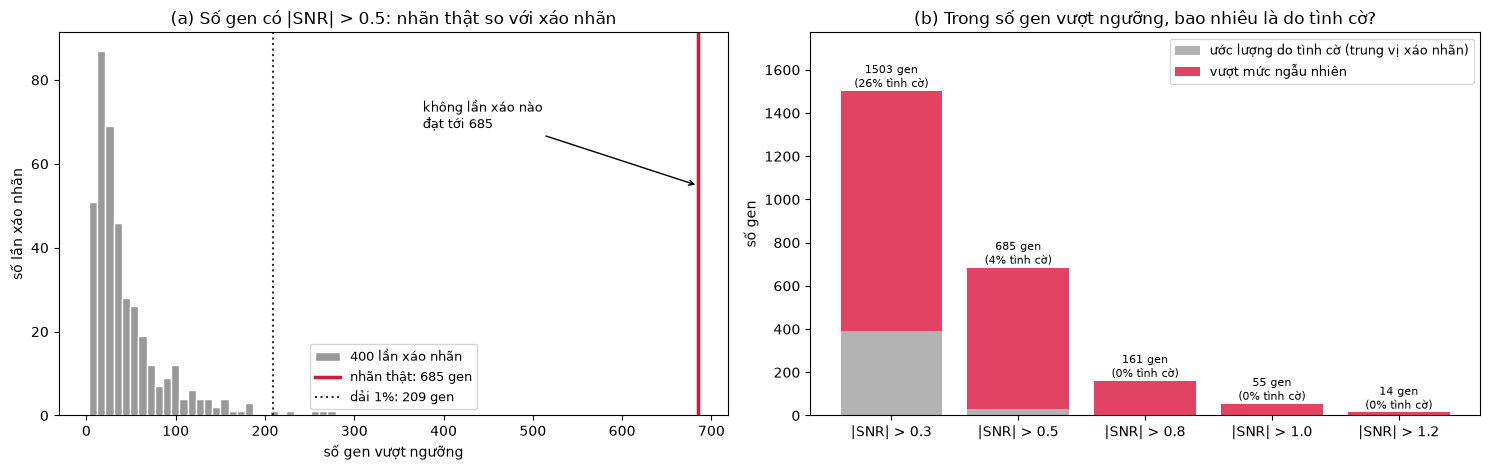

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

# (a) 400 lần "đoán bừa" so với nhãn thật, tại một ngưỡng cố định
t0 = 0.5
i0 = np.where(np.isclose(thresholds, t0))[0][0]
null = perm[:, 0, i0]
ax = axes[0]
ax.hist(null, bins=30, color="0.6", edgecolor="white", label=f"{N_PERM} lần xáo nhãn")
ax.axvline(real[0, i0], color="crimson", lw=2.5, label=f"nhãn thật: {real[0, i0]:.0f} gen")
ax.axvline(band_1[0, i0], color="0.2", ls=":", lw=1.5, label=f"dải 1%: {band_1[0, i0]:.0f} gen")
ax.annotate(f"không lần xáo nào\nđạt tới {real[0, i0]:.0f}", xy=(real[0, i0], ax.get_ylim()[1] * 0.6),
            xytext=(real[0, i0] * 0.55, ax.get_ylim()[1] * 0.75), arrowprops={"arrowstyle": "->"}, fontsize=9)
ax.set(title=f"(a) Số gen có |SNR| > {t0}: nhãn thật so với xáo nhãn",
       xlabel="số gen vượt ngưỡng", ylabel="số lần xáo nhãn")
ax.legend(fontsize=9)

# (b) Mỗi ngưỡng: phần do tình cờ (trung vị hoán vị) và phần vượt mức ngẫu nhiên
show_t = [0.3, 0.5, 0.8, 1.0, 1.2]
idx = [np.where(np.isclose(thresholds, t))[0][0] for t in show_t]
chance = np.minimum(band_50[0, idx], real[0, idx])
beyond = real[0, idx] - chance
x = np.arange(len(show_t))
ax = axes[1]
ax.bar(x, chance, color="0.7", label="ước lượng do tình cờ (trung vị xáo nhãn)")
ax.bar(x, beyond, bottom=chance, color="crimson", alpha=0.8, label="vượt mức ngẫu nhiên")
for xi, c, b in zip(x, chance, beyond):
    ax.text(xi, c + b, f"{c + b:.0f} gen\n({c / (c + b):.0%} tình cờ)", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x, [f"|SNR| > {t}" for t in show_t])
ax.set(title="(b) Trong số gen vượt ngưỡng, bao nhiêu là do tình cờ?", ylabel="số gen",
       ylim=(0, real[0, idx].max() * 1.18))
ax.legend(fontsize=9)

fig.tight_layout()
fig.savefig(REPORT_FIG_DIR / "F6b_neighborhood_simple_report.png", dpi=150, bbox_inches="tight")
plt.show()


**Kết quả:**

| Ngưỡng \|SNR\| | Nhãn thật | Trung vị xáo nhãn | Dải 1% | Thật / dải 1% |
|---|---|---|---|---|
| 0,3 | 1503 | 389 | 1001 | 1,5 |
| 0,5 | 685 | 29 | 209 | 3,3 |
| 0,8 | 161 | 0 | 6 | 26,8 |
| 1,0 | 55 | 0 | 1 | 55 |

- Ở mọi ngưỡng |SNR| ≥ 0,3, đường nhãn thật **nằm trên dải 1%**, và khoảng cách càng lớn khi ngưỡng tăng. Từ |SNR| > 1 gần như không lần xáo nhãn nào có gen, trong khi nhãn thật có 55 gen.
- **Không lần nào trong 400 lần** xáo nhãn cho nhiều gen bằng nhãn thật → **p < 1/400 = 0,0025**.
- Cả gen cao ở ALL lẫn gen cao ở AML đều vượt dải 1% từ ngưỡng ≈ 0,4 → mỗi lớp đều có nhóm gen đặc trưng riêng.
- Hình (b): ở |SNR| > 0,5 chỉ ~4% số gen (29/685) có thể là do tình cờ; từ 0,8 trở lên gần như 0%.
- Số gen vượt mức ngẫu nhiên (chênh lớn nhất giữa nhãn thật và dải 1%): **≈ 536 gen**. Bài báo báo cáo ~1100 gen; con số của nhóm nhỏ hơn vì chỉ dùng 3541 gen sau lọc (bài báo: 6817 gen) và bài báo không nêu chính xác cách đếm.

**→ Bằng chứng 1 ủng hộ H1:** có nhiều gen tương quan với phân biệt ALL/AML hơn hẳn mức ngẫu nhiên.

*Ghi chú:* ở ngưỡng < 0,3, đường "cao ở ALL" và "cao ở AML" nằm dưới dải. Đây là điều bình thường: khi xáo nhãn, các gen chia gần đều hai dấu, còn với nhãn thật có 1943 gen nghiêng về AML và 1598 về ALL. Ở ngưỡng thấp, phép đếm chỉ phản ánh dấu của SNR nên không dùng để kết luận.

### 6.5 Phân bố SNR: nhãn thật so với xáo nhãn

Minh họa trực quan cho 6.4 (Bài 5.1 — histogram dùng để so sánh hình dạng phân bố). Thay vì đếm số gen vượt từng ngưỡng, ta nhìn **toàn bộ phân bố SNR** của 3541 gen:
- **Nhãn thật:** SNR tính với nhãn ALL/AML thật.
- **Xáo nhãn:** gộp SNR của 20 lần xáo nhãn — đây là hình dạng phân bố khi nhãn không liên quan đến gen.

Nếu H1 đúng, phân bố của nhãn thật phải **rộng hơn**, với **hai đuôi dày hơn** (nhiều gen có |SNR| lớn).

                       nhãn thật  xáo nhãn (20 lần gộp)
độ lệch chuẩn của SNR      0.391                  0.188
tỷ lệ gen |SNR| > 0.5      0.193                  0.011
tỷ lệ gen |SNR| > 0.8      0.045                  0.000
|SNR| lớn nhất             1.729                  1.038


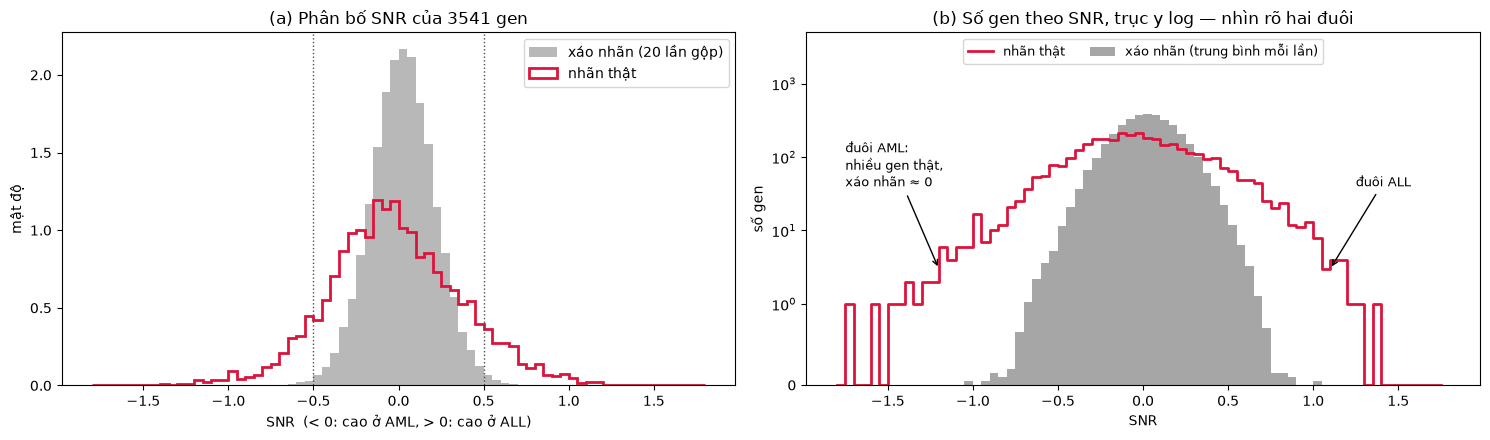

In [8]:
# --- SNR với nhãn thật so với SNR khi xáo nhãn ---
snr_real = stats.set_index("probe_id").loc[Xtr.columns, "snr"].to_numpy()

# Gộp SNR của 20 lần xáo nhãn để histogram "ngẫu nhiên" ổn định (một lần xáo thì hình còn gồ ghề)
N_SHOW = 20
snr_null = np.concatenate([snr(Xtr_np, rng.permutation(is_all)) for _ in range(N_SHOW)])

summary = pd.DataFrame({
    "nhãn thật": [snr_real.std(), np.mean(np.abs(snr_real) > 0.5), np.mean(np.abs(snr_real) > 0.8),
                  np.abs(snr_real).max()],
    f"xáo nhãn ({N_SHOW} lần gộp)": [snr_null.std(), np.mean(np.abs(snr_null) > 0.5),
                                     np.mean(np.abs(snr_null) > 0.8), np.abs(snr_null).max()],
}, index=["độ lệch chuẩn của SNR", "tỷ lệ gen |SNR| > 0.5", "tỷ lệ gen |SNR| > 0.8", "|SNR| lớn nhất"])
print(summary.round(3).to_string())

# --- Hình ---
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
bins = np.linspace(-1.8, 1.8, 73)

# (a) Hai phân bố chồng lên nhau (mật độ, để so được dù số gen khác nhau)
ax = axes[0]
ax.hist(snr_null, bins=bins, density=True, color="0.65", alpha=0.8, label=f"xáo nhãn ({N_SHOW} lần gộp)")
ax.hist(snr_real, bins=bins, density=True, histtype="step", color="crimson", lw=2, label="nhãn thật")
for v in (-0.5, 0.5):
    ax.axvline(v, color="0.3", ls=":", lw=1)
ax.set(title="(a) Phân bố SNR của 3541 gen", xlabel="SNR  (< 0: cao ở AML, > 0: cao ở ALL)", ylabel="mật độ")
ax.legend()

# (b) Phóng to hai đuôi: số gen có |SNR| lớn (trục y log)
ax = axes[1]
w = np.diff(bins)[0]
cnt_real, _ = np.histogram(snr_real, bins)
cnt_null, _ = np.histogram(snr_null, bins)
ax.bar(bins[:-1], cnt_null / N_SHOW, width=w, align="edge", color="0.65", label="xáo nhãn (trung bình mỗi lần)")
ax.step(bins[:-1], cnt_real, where="post", color="crimson", lw=2, label="nhãn thật")
ax.set_yscale("symlog", linthresh=1)
ax.set_ylim(0, 5000)                               # chừa chỗ phía trên cho chú thích
ax.set(title="(b) Số gen theo SNR, trục y log — nhìn rõ hai đuôi",
       xlabel="SNR", ylabel="số gen")
ax.annotate("đuôi AML:\nnhiều gen thật,\nxáo nhãn ≈ 0", xy=(-1.2, 3), xytext=(-1.75, 40), fontsize=9,
            arrowprops={"arrowstyle": "->"})
ax.annotate("đuôi ALL", xy=(1.1, 3), xytext=(1.25, 40), fontsize=9, arrowprops={"arrowstyle": "->"})
ax.legend(loc="upper center", ncol=2, fontsize=9)

fig.tight_layout()
fig.savefig(REPORT_FIG_DIR / "F6c_snr_histogram_report.png", dpi=150, bbox_inches="tight")
plt.show()


**Kết quả:**
- Phân bố SNR của nhãn thật **rộng gấp đôi** phân bố khi xáo nhãn (độ lệch chuẩn 0,39 so với 0,19).
- **19,3%** số gen có |SNR| > 0,5 với nhãn thật, so với **1,1%** khi xáo nhãn (gấp ~18 lần); |SNR| > 0,8: 4,5% so với 0%.
- Khi xáo nhãn, |SNR| không bao giờ vượt quá ~1,04; với nhãn thật có gen đạt 1,73 (CST3).
- Hình (b) với trục y log cho thấy rõ: ở hai đuôi (|SNR| > 1), nhãn thật có hàng chục gen trong khi xáo nhãn gần như không có. **Đuôi AML dài hơn đuôi ALL**, khớp với nhận xét ở 6.3 (nhóm ALL gồm B-ALL và T-ALL nên gen phía ALL có SNR thấp hơn).

**→ Minh họa trực quan cho H1:** việc phân biệt ALL/AML làm xuất hiện rất nhiều gen có SNR lớn — điều không xảy ra khi nhãn ngẫu nhiên.


### 6.6 Welch t-test, FDR và volcano plot — bằng chứng chính thứ hai cho H1

Dùng p-value và q-value đã tính ở 6.3:
- Đếm số gen có **q < 0,05** (Benjamini–Hochberg), tách theo phía ALL/AML, và số gen vừa q < 0,05 vừa chênh lệch ≥ 2 lần (|log_fc| ≥ log10 2 ≈ 0,301).
- **Mức ngẫu nhiên cho t-test:** xáo nhãn 100 lần, mỗi lần làm lại Welch + Benjamini–Hochberg và đếm số gen q < 0,05.
- **Volcano plot:** trục x = `log_fc` (mean AML − mean ALL, thang log10), trục y = −log10(p). Đường ngang là ngưỡng q = 0,05; đường dọc là ngưỡng chênh 2 lần.

**Ủng hộ H1 khi:** nhãn thật cho nhiều gen q < 0,05, còn nhãn xáo gần như không có.

           q < 0.05  q < 0.05 và chênh ≥ 2 lần
cao ở ALL       347                        154
cao ở AML       280                        152
Tổng            627                        306


D:\Project\University\IT5424_QTDL-va-TQH\Golub-project\.venv\Lib\site-packages\scipy\stats\_axis_nan_policy.py:644: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, axis=axis, **kwds)



Nhãn thật: 627 gen q < 0.05
Xáo nhãn (100 lần): trung vị 0 gen, lớn nhất 3 gen, số lần có ≥ 1 gen: 4/100


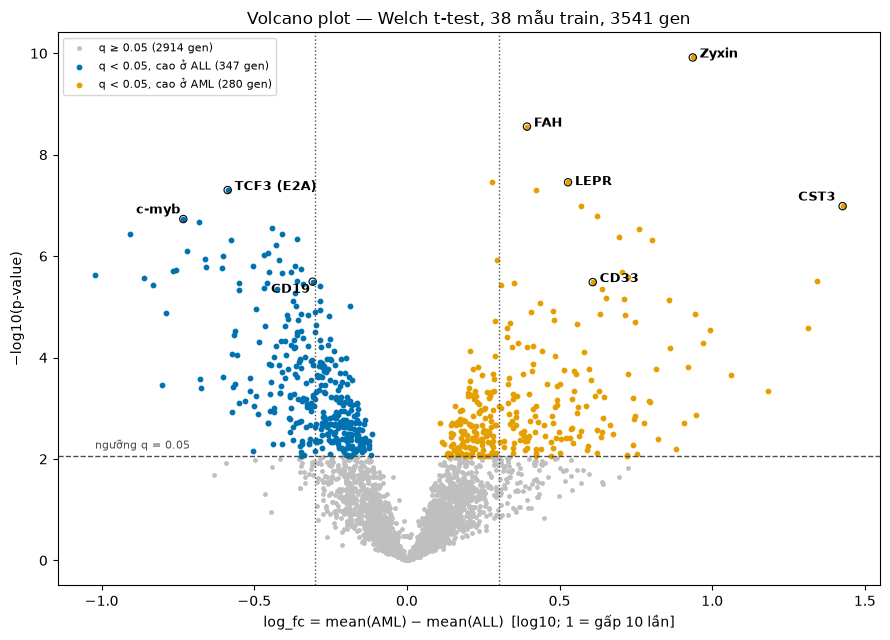

In [9]:
from src.config import REPORT_FIG_DIR

# --- Đếm số gen có ý nghĩa ---
FC2 = np.log10(2)                                   # chênh ≥ 2 lần  ⇔  |log_fc| ≥ 0.301
sig = stats["q_value"] < 0.05
big = stats["log_fc"].abs() >= FC2
count = pd.DataFrame({
    "q < 0.05": [ (sig & (stats["higher_in"] == s)).sum() for s in ["ALL", "AML"] ],
    "q < 0.05 và chênh ≥ 2 lần": [ (sig & big & (stats["higher_in"] == s)).sum() for s in ["ALL", "AML"] ],
}, index=["cao ở ALL", "cao ở AML"])
count.loc["Tổng"] = count.sum()
print(count.to_string())

# --- Mức ngẫu nhiên cho t-test: xáo nhãn rồi làm lại Welch + BH ---
N_BH = 100
null_sig = np.array([
    (multipletests(welch(Xtr_np, rng.permutation(is_all))[1], method="fdr_bh")[1] < 0.05).sum()
    for _ in range(N_BH)
])
print(f"\nNhãn thật: {sig.sum()} gen q < 0.05")
print(f"Xáo nhãn ({N_BH} lần): trung vị {np.median(null_sig):.0f} gen, lớn nhất {null_sig.max()} gen, "
      f"số lần có ≥ 1 gen: {(null_sig > 0).sum()}/{N_BH}")

# --- Volcano plot ---
x = stats["log_fc"].to_numpy()
y = -np.log10(stats["p_value"].to_numpy())
p_cut = stats.loc[sig, "p_value"].max()            # p lớn nhất còn đạt q < 0.05

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.scatter(x[~sig], y[~sig], s=6, color="0.75", label=f"q ≥ 0.05 ({(~sig).sum()} gen)")
for side in ["ALL", "AML"]:
    m = (sig & (stats["higher_in"] == side)).to_numpy()
    ax.scatter(x[m], y[m], s=10, color=PALETTE[side], label=f"q < 0.05, cao ở {side} ({m.sum()} gen)")
ax.axhline(-np.log10(p_cut), color="0.3", ls="--", lw=1)
ax.text(x.min(), -np.log10(p_cut) + 0.15, "ngưỡng q = 0.05", fontsize=8, color="0.3")
for v in (-FC2, FC2):
    ax.axvline(v, color="0.3", ls=":", lw=1)

# Ghi tên các gen đã biết (tên gen, độ lệch nhãn để không đè nhau)
lab = {
    "X95735_at": ("Zyxin", (5, 0)),        "M27891_at": ("CST3", (-32, 4)),
    "M23197_at": ("CD33", (5, 0)),         "M55150_at": ("FAH", (5, 0)),
    "Y12670_at": ("LEPR", (5, -2)),        "M31523_at": ("TCF3 (E2A)", (5, 0)),
    "U22376_cds2_s_at": ("c-myb", (-34, 4)), "M28170_at": ("CD19", (-30, -8)),
}
for pid, (name, off) in lab.items():
    r = stats.loc[stats["probe_id"] == pid].iloc[0]
    ax.scatter(r["log_fc"], -np.log10(r["p_value"]), s=28, facecolors="none", edgecolors="black", lw=0.8)
    ax.annotate(name, (r["log_fc"], -np.log10(r["p_value"])), xytext=off,
                textcoords="offset points", fontsize=9, weight="bold")

ax.set(title=f"Volcano plot — Welch t-test, 38 mẫu train, {len(stats)} gen",
       xlabel="log_fc = mean(AML) − mean(ALL)  [log10; 1 = gấp 10 lần]",
       ylabel="−log10(p-value)")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(REPORT_FIG_DIR / "volcano_report.png", dpi=150, bbox_inches="tight")
plt.show()


**Kết quả:**
- **627/3541 gen** có q < 0,05 (347 cao ở ALL, 280 cao ở AML); **306 gen** vừa q < 0,05 vừa chênh lệch ≥ 2 lần.
- Mức ngẫu nhiên: làm lại Welch + Benjamini–Hochberg với 100 lần xáo nhãn → trung vị **0 gen**, nhiều nhất 3 gen, chỉ 4/100 lần có ít nhất 1 gen. Nhãn thật (627 gen) vượt xa mức này.
- Volcano plot: hai nhóm gen có ý nghĩa tách rõ khỏi phần còn lại; các gen đã biết nằm ở đầu mỗi phía (AML: Zyxin, CST3, CD33, LEPR, FAH; ALL: TCF3/E2A, c-myb, CD19).
- Theo q-value, phía ALL có nhiều gen hơn (khác với xếp hạng SNR ở 6.3) vì t-test tính đến cỡ mẫu: nhóm ALL có 27 mẫu nên trung bình được ước lượng chính xác hơn.

**→ Bằng chứng 2 ủng hộ H1:** sau khi kiểm soát tỷ lệ phát hiện sai ở 5%, vẫn có hàng trăm gen khác biệt có ý nghĩa giữa ALL và AML, trong khi với nhãn ngẫu nhiên gần như không có.

### 6.7 Box plot top gen theo ALL/AML

Minh họa trực quan (Bài 5.1 — box plot trả lời câu hỏi *"Is a factor significant? Does the location differ between subgroups?"*). Vẽ **4 gen cao ở ALL** và **4 gen cao ở AML** có |SNR| lớn nhất. Mỗi điểm là một bệnh nhân, hình dạng điểm theo phân nhóm: B-ALL ●, T-ALL ▲, AML ■.

Kèm theo: **tỷ lệ phân sai khi chỉ dùng 1 gen** — đặt ngưỡng ở trung điểm hai trung bình, đếm số bệnh nhân bị xếp nhầm nhóm.


 rank         probe_id                   description     snr  log_fc  q_value
    6 U22376_cds2_s_at C-myb gene extracted from Hu…  1.3719 -0.7323   0.0001
   11        M31523_at  TCF3 Transcription factor 3…  1.2531 -0.5870   0.0000
   13        X74262_at RETINOBLASTOMA BINDING PROTE…  1.2064 -0.6814   0.0001
   19        M89957_at IGB Immunoglobulin-associate…  1.1762 -0.7562   0.0002
    1        M27891_at CST3 Cystatin C (amyloid ang… -1.7289  1.4271   0.0000
    2        X95735_at                         Zyxin -1.5967  0.9363   0.0000
    3   U50136_rna1_at Leukotriene C4 synthase (LTC… -1.4959  0.4223   0.0000
    4        M23197_at CD33 CD33 antigen (different… -1.4127  0.6087   0.0002


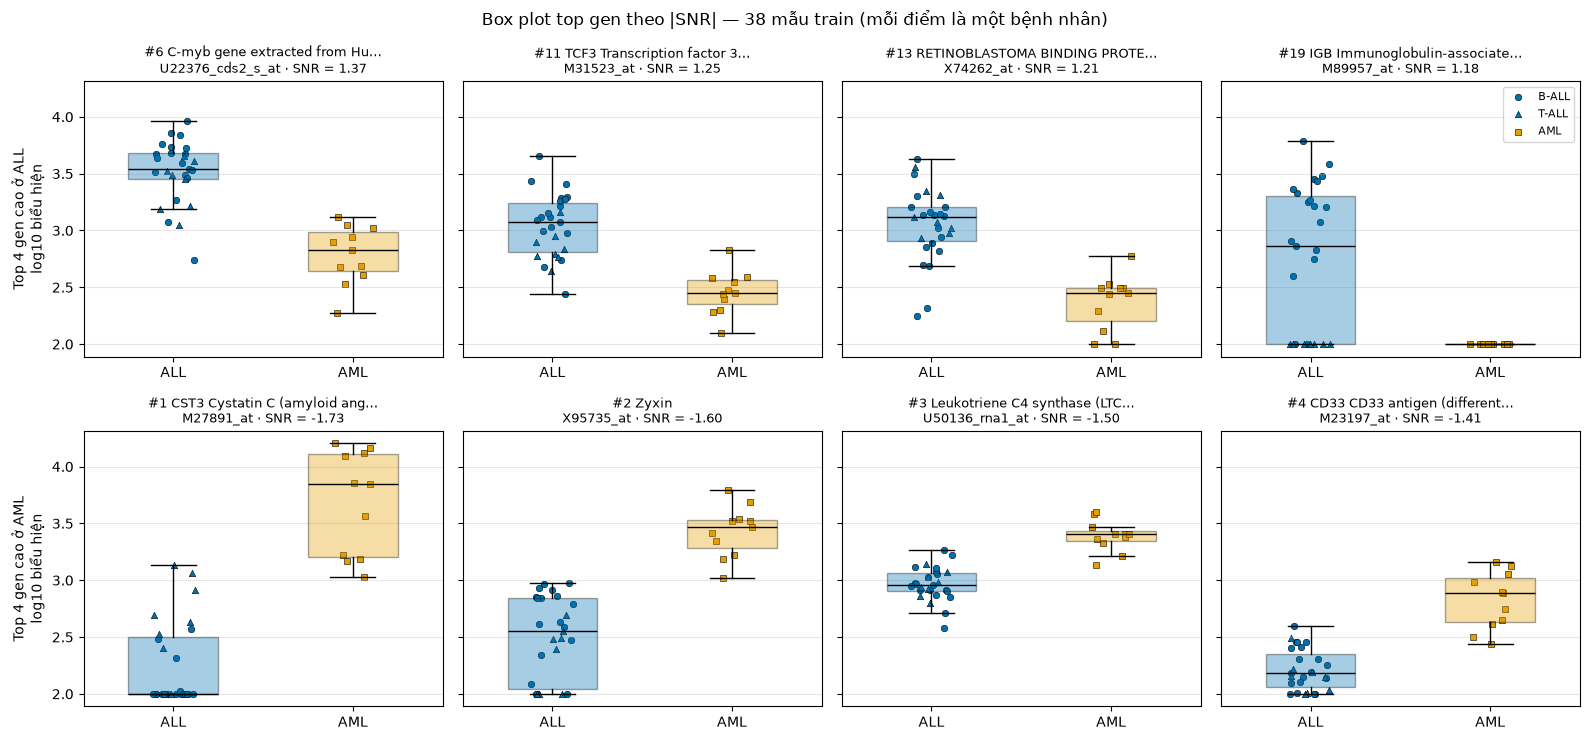


 rank         probe_id higher_in  tỷ lệ phân sai (1 gen)
    6 U22376_cds2_s_at       ALL                   0.079
   11        M31523_at       ALL                   0.132
   13        X74262_at       ALL                   0.132
   19        M89957_at       ALL                   0.263
    1        M27891_at       AML                   0.053
    2        X95735_at       AML                   0.053
    3   U50136_rna1_at       AML                   0.079
    4        M23197_at       AML                   0.079


In [10]:
from src.config import REPORT_FIG_DIR

def short_name(desc: str, n: int = 28) -> str:
    """Tên ngắn cho tiêu đề: bỏ tiền tố 'GB DEF = ', cắt n ký tự."""
    desc = desc.replace("GB DEF = ", "")
    return desc if len(desc) <= n else desc[:n].rstrip() + "…"

K = 4
top_all = stats[stats["higher_in"] == "ALL"].head(K)      # stats đã xếp theo |SNR| giảm dần
top_aml = stats[stats["higher_in"] == "AML"].head(K)
top = pd.concat([top_all, top_aml])
print(top[["rank", "probe_id", "description", "snr", "log_fc", "q_value"]]
      .assign(description=lambda d: d["description"].map(short_name)).round(4).to_string(index=False))

subtype_tr = samples.loc[tr, "subtype"]
markers = {"B-ALL": "o", "T-ALL": "^", "AML": "s"}
jit = np.random.default_rng(RANDOM_SEED)                  # rng riêng cho jitter, không ảnh hưởng rng chính

fig, axes = plt.subplots(2, K, figsize=(16, 7.5), sharey=True)
for ax, (_, g) in zip(axes.ravel(), top.iterrows()):
    vals = [Xtr.loc[ytr == c, g["probe_id"]] for c in ["ALL", "AML"]]
    bp = ax.boxplot(vals, widths=0.5, patch_artist=True, showfliers=False,
                    medianprops={"color": "black"})
    for patch, c in zip(bp["boxes"], ["ALL", "AML"]):
        patch.set_facecolor(PALETTE[c]); patch.set_alpha(0.35)
    # Từng bệnh nhân: hình dạng điểm theo phân nhóm (B-ALL ●, T-ALL ▲, AML ■)
    for pos, c in enumerate(["ALL", "AML"], start=1):
        for st_name, mk in markers.items():
            m = (ytr == c) & (subtype_tr == st_name)
            if m.any():
                ax.scatter(pos + jit.uniform(-0.12, 0.12, m.sum()), Xtr.loc[m, g["probe_id"]],
                           marker=mk, s=22, color=PALETTE[c], edgecolors="black", linewidths=0.4,
                           label=st_name)
    ax.set_xticks([1, 2], ["ALL", "AML"])
    ax.set_title(f"#{g['rank']} {short_name(g['description'])}\n{g['probe_id']} · SNR = {g['snr']:.2f}",
                 fontsize=9)
    ax.grid(axis="y", alpha=0.3)
axes[0, 0].set_ylabel(f"Top {K} gen cao ở ALL\nlog10 biểu hiện")
axes[1, 0].set_ylabel(f"Top {K} gen cao ở AML\nlog10 biểu hiện")
handles, labels = axes[1, 0].get_legend_handles_labels()
by_label = dict(zip(labels, handles))
axes[0, -1].legend(by_label.values(), by_label.keys(), fontsize=8, loc="upper right")
fig.suptitle("Box plot top gen theo |SNR| — 38 mẫu train (mỗi điểm là một bệnh nhân)")
fig.tight_layout()
fig.savefig(REPORT_FIG_DIR / "boxplot_top_genes_report.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Mức độ chồng lấn: tỷ lệ bệnh nhân bị "đặt nhầm phía" nếu chỉ dùng 1 gen với ngưỡng là trung điểm ---
def overlap(pid: str, higher: str) -> float:
    v = Xtr[pid]
    cut = (v[ytr == "ALL"].mean() + v[ytr == "AML"].mean()) / 2
    pred = np.where(v > cut, higher, "AML" if higher == "ALL" else "ALL")
    return (pred != ytr.to_numpy()).mean()

top_err = top.assign(**{"tỷ lệ phân sai (1 gen)": [overlap(p, h) for p, h in zip(top["probe_id"], top["higher_in"])]})
print("\n" + top_err[["rank", "probe_id", "higher_in", "tỷ lệ phân sai (1 gen)"]].round(3).to_string(index=False))


**Kết quả:**
- Ở cả 8 gen, hộp ALL và hộp AML **gần như không chồng lấn**: mức biểu hiện tách hẳn giữa hai nhóm.
- Chỉ với **một gen**, đã phân đúng 74–95% bệnh nhân train: tốt nhất CST3 và Zyxin chỉ sai 5,3% (2/38); c-myb, LTC4S, CD33 sai 7,9% (3/38); TCF3, RbAp48 sai 13,2%; IGB sai 26,3%.
- Bốn gen phía AML (CST3, Zyxin, LTC4S, CD33) đều nằm trong danh sách 50 gen của Golub; CD33 là dấu ấn bề mặt dùng trong chẩn đoán AML trên lâm sàng.
- **Gen IGB (#19):** B-ALL biểu hiện cao, nhưng **T-ALL (▲) nằm ở mức sàn 2,0 giống AML**. Đây là gen đặc trưng của tế bào B, không phải của mọi ALL — minh họa trực tiếp vì sao nhóm ALL có độ dao động lớn và gen phía ALL có SNR thấp hơn (6.3). IGB có tỷ lệ phân sai cao nhất (26%) chính vì 8 mẫu T-ALL.
- Ngược lại, **CST3**: các mẫu T-ALL cao hơn B-ALL, nhưng vẫn thấp hơn AML.

**→ Minh họa trực quan cho H1:** những gen đứng đầu bảng xếp hạng thực sự tách hai nhóm bệnh nhân rõ ràng, đến mức một gen đơn lẻ đã gần đủ để phân loại.

### 6.8 PCA trên toàn bộ gen — kiểm tra không giám sát

Bài 5.1 và 5.2: giảm chiều bằng PCA sau khi chuẩn hóa z-score từng gen. Dùng **toàn bộ 3541 gen**, không chọn gen theo nhãn; nhãn chỉ dùng để tô màu sau khi đã có kết quả. PCA được fit trên 38 mẫu train, sau đó chiếu 34 mẫu test bằng chính PCA đó.

Câu hỏi: khác biệt ALL/AML có phải là một nguồn biến thiên lớn của **toàn bộ** dữ liệu không? Nếu có, nó được phản ánh qua rất nhiều gen — đúng với tinh thần của H1.

Tỷ lệ phương sai giải thích: PC1 16.2%, PC2 13.7%, PC3 7.7%, PC4 5.6%, PC5 4.6%

Mỗi thành phần chính có tách ALL/AML không?
     phương sai giải thích  t (ALL vs AML)       p
PC1                 0.1617         -0.1780  0.8602
PC2                 0.1374          5.7947  0.0000
PC3                 0.0769         -3.8589  0.0016
PC4                 0.0561          0.4850  0.6308
PC5                 0.0455         -0.0453  0.9645


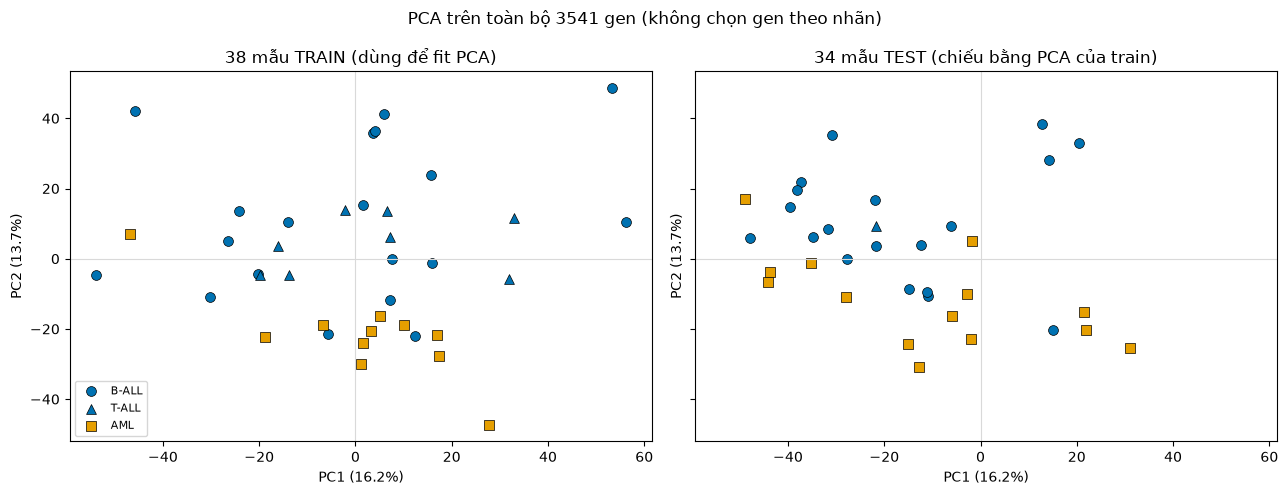


Tương quan PC1 với trung vị biểu hiện của mẫu: 0.99  |  PC2: -0.05


In [11]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from src.config import REPORT_FIG_DIR

# PCA trên TOÀN BỘ 3541 gen — không chọn gen theo nhãn, nhãn chỉ dùng để tô màu sau đó
scaler = StandardScaler().fit(Xtr)                    # chuẩn hóa z-score theo gen (Bài 5.2), fit trên train
pca = PCA(n_components=5, random_state=RANDOM_SEED).fit(scaler.transform(Xtr))
pc_tr = pd.DataFrame(pca.transform(scaler.transform(Xtr))[:, :2], index=Xtr.index, columns=["PC1", "PC2"])

te = samples["split"] == "test"
Xte, yte = X.loc[te], samples.loc[te, "class"]
pc_te = pd.DataFrame(pca.transform(scaler.transform(Xte))[:, :2], index=Xte.index, columns=["PC1", "PC2"])

ev = pca.explained_variance_ratio_
print("Tỷ lệ phương sai giải thích:", ", ".join(f"PC{i+1} {v:.1%}" for i, v in enumerate(ev)))

# PC nào liên quan đến ALL/AML? So sánh điểm PC giữa hai lớp (Welch t-test)
pcs_all = pd.DataFrame(pca.transform(scaler.transform(Xtr)), index=Xtr.index,
                       columns=[f"PC{i+1}" for i in range(5)])
assoc = pd.DataFrame({
    "phương sai giải thích": ev,
    "t (ALL vs AML)": [st.ttest_ind(pcs_all.loc[ytr == "ALL", c], pcs_all.loc[ytr == "AML", c], equal_var=False)[0]
                      for c in pcs_all],
    "p": [st.ttest_ind(pcs_all.loc[ytr == "ALL", c], pcs_all.loc[ytr == "AML", c], equal_var=False)[1]
          for c in pcs_all],
}, index=pcs_all.columns)
print("\nMỗi thành phần chính có tách ALL/AML không?")
print(assoc.round(4).to_string())

# Hình: train (fit PCA) và test (chiếu bằng PCA của train)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, pc, y, ttl in [(axes[0], pc_tr, ytr, "38 mẫu TRAIN (dùng để fit PCA)"),
                       (axes[1], pc_te, yte, "34 mẫu TEST (chiếu bằng PCA của train)")]:
    sub = samples.loc[pc.index, "subtype"]
    for c in ["ALL", "AML"]:
        for stp, mk in [("B-ALL", "o"), ("T-ALL", "^"), ("AML", "s")]:
            m = (y == c) & (sub == stp)
            if m.any():
                ax.scatter(pc.loc[m, "PC1"], pc.loc[m, "PC2"], marker=mk, s=50, color=PALETTE[c],
                           edgecolors="black", linewidths=0.5, label=stp)
    ax.set(title=ttl, xlabel=f"PC1 ({ev[0]:.1%})", ylabel=f"PC2 ({ev[1]:.1%})")
    ax.axhline(0, color="0.85", lw=0.8); ax.axvline(0, color="0.85", lw=0.8)
axes[0].legend(fontsize=8)
fig.suptitle(f"PCA trên toàn bộ {Xtr.shape[1]} gen (không chọn gen theo nhãn)")
fig.tight_layout()
fig.savefig(REPORT_FIG_DIR / "pca_all_genes_report.png", dpi=150, bbox_inches="tight")
plt.show()

# PC1 phản ánh điều gì? So với "độ sáng chung" của từng chip (trung vị biểu hiện của mẫu)
print(f"\nTương quan PC1 với trung vị biểu hiện của mẫu: {np.corrcoef(pcs_all['PC1'], Xtr.median(axis=1))[0, 1]:.2f}"
      f"  |  PC2: {np.corrcoef(pcs_all['PC2'], Xtr.median(axis=1))[0, 1]:.2f}")


**Kết quả:**
- **PC1 (16,2%) không liên quan đến ALL/AML** (p = 0,86): nó tương quan 0,99 với trung vị biểu hiện của từng mẫu, tức phản ánh **độ sáng chung của chip** — một yếu tố kỹ thuật.
- **PC2 (13,7%) tách rõ ALL và AML** (t = 5,8, p < 10⁻⁴): ALL ở phía trên, AML ở phía dưới. PC3 (7,7%) cũng liên quan (p = 0,002).
- Chiếu 34 mẫu test bằng PCA của train, ALL và AML vẫn tách theo PC2 → cấu trúc này lặp lại trên bệnh nhân mới.

**→ Bằng chứng không giám sát cho H1:** ngay cả khi không chọn gen, khác biệt ALL/AML là **nguồn biến thiên lớn thứ hai** của toàn bộ dữ liệu (sau yếu tố kỹ thuật), nghĩa là nó được phản ánh qua rất nhiều gen. PC1 cũng cho thấy dữ liệu có biến thiên kỹ thuật đáng kể giữa các chip.

### 6.9 Hạn chế

Các điểm yếu của dữ liệu và phương pháp có thể ảnh hưởng đến kết luận H1:

| # | Hạn chế | Ảnh hưởng | Xử lý / kiểm tra |
|---|---|---|---|
| 1 | **Batch effect:** trong tập train, mọi ALL từ DFCI, mọi AML từ CALGB — lớp trùng hoàn toàn với nguồn mẫu | 6.4 và 6.6 chỉ chứng minh gen khác biệt giữa **hai nhóm mẫu**, chưa tách được do **bệnh** hay do **bệnh viện** ("Correlation does not imply causality" — Bài 4) | Kiểm tra trên St-Jude (6.9b) |
| 2 | **Cỡ mẫu nhỏ:** 38 mẫu train (27/11), p ≫ n | Ước lượng trung bình, độ lệch chuẩn của nhóm AML (11 mẫu) kém ổn định; xếp hạng gen có thể thay đổi nếu đổi vài mẫu | Bỏ mẫu 21 (6.9c); độ ổn định chọn gen làm ở việc 2.2 |
| 3 | **Nhóm ALL không đồng nhất:** 19 B-ALL + 8 T-ALL | Gen đặc trưng B-ALL (IGB, TCL1, CD19) có SNR thấp hơn; danh sách top theo \|SNR\| lệch về AML | Chọn 25 gen mỗi phía như Golub (6.3, 6.7) |
| 4 | **Bộ lọc gen tính trên cả 72 mẫu** | `X_log10_filtered` (3571 gen) dùng thông tin tập test; lọc chỉ trên train còn 3052 gen | Chấp nhận được cho phân tích khám phá; mô hình ở giai đoạn 2 phải lọc trong Pipeline |
| 5 | **Ít gen hơn bài báo:** 3541 gen (sau lọc, bỏ AFFX, bỏ gen hằng số) so với 6817 | Số gen vượt mức ngẫu nhiên (6.4) không so trực tiếp được với ~1100 của bài báo | Ghi rõ khi so sánh |
| 6 | **Nhiều probe cho một gen:** 926 probe dùng chung 424 mô tả | Đếm theo probe có thể đếm một gen nhiều lần | Gộp theo `description` khi so với 50 gen của Golub (6.10) |
| 7 | **Thang đo MAS 4.0 và ngưỡng [100, 16 000]:** ~19% giá trị ở mức sàn | Gen biểu hiện thấp bị mất thông tin; một số gen thành hằng số trên train (8 gen bị bỏ) | Theo quy trình chuẩn của Dudoit et al. (2002) |
| 8 | **Đã dùng tập test để kiểm tra** (6.9b) | Tập test không còn "hoàn toàn chưa nhìn"; chỉ kiểm tra hướng khác biệt, không chọn gen hay tham số trên test | Ghi trong ghi chú bàn giao cho TV1, TV2 |

Ô code dưới đây gồm ba phần:
- **(a)** Kiểm chứng hạn chế 1 bằng kiểm định chi-square trên bảng lớp × nguồn của tập train.
- **(b)** Kiểm tra trên **St-Jude** (tập test; cùng một nguồn có cả 3 ALL và 5 AML): dùng 50 gen chọn trên train (25 mỗi phía), xem các gen có giữ đúng chiều khác biệt không, và "điểm AML" (trung bình z của 25 gen AML trừ 25 gen ALL; z và ngưỡng đều lấy từ train) có tách đúng ALL/AML không. Tập test chỉ dùng để kiểm tra, không chọn gen hay ước lượng tham số nào trên đó.
- **(c)** Độ vững khi bỏ mẫu 21 (`qc_outlier`).

(a) Bảng chéo lớp × nguồn (train):
source  CALGB  DFCI
class              
ALL         0    27
AML        11     0
Chi-square = 33.29, bậc tự do = 1, p = 7.9e-09 -> lớp và nguồn phụ thuộc hoàn toàn

(b) St-Jude (test): 8 mẫu — {'AML': 5, 'ALL': 3}
b1. Số gen (trong 50) giữ đúng chiều ALL/AML ở St-Jude: 46/50
b2. Điểm AML > 0.62 -> xếp vào AML: đúng 97% trên 34 mẫu test, 100% trên 8 mẫu St-Jude
    Mẫu test bị xếp sai: [66]


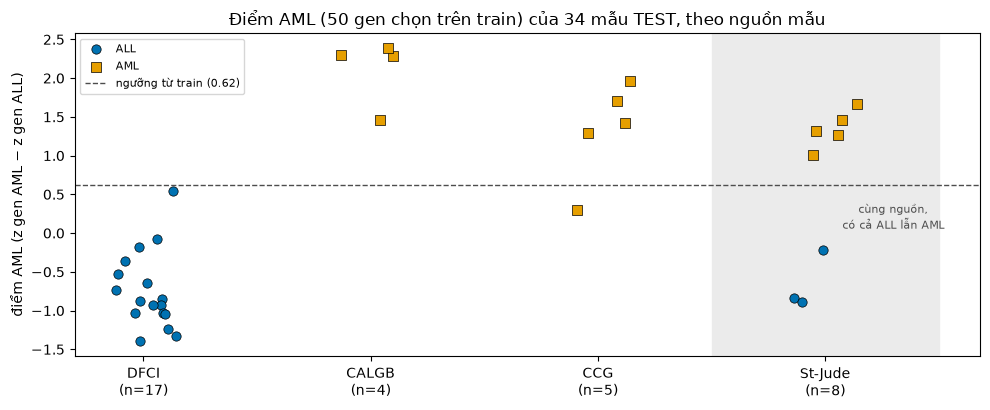


(c) Bỏ mẫu 21 (còn 3540 gen không hằng số): tương quan SNR với bản đầy đủ = 0.9971; top 50 trùng 46/50; số gen q < 0.05: 627 -> 586


D:\Project\University\IT5424_QTDL-va-TQH\Golub-project\.venv\Lib\site-packages\scipy\stats\_axis_nan_policy.py:644: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, axis=axis, **kwds)


In [12]:
from src.config import REPORT_FIG_DIR

# ============ (a) Lớp và nguồn mẫu trùng nhau trong tập train ============
ct = pd.crosstab(samples.loc[tr, "class"], samples.loc[tr, "source"])
chi2, p_chi, dof, _ = st.chi2_contingency(ct)
print("(a) Bảng chéo lớp × nguồn (train):")
print(ct.to_string())
print(f"Chi-square = {chi2:.2f}, bậc tự do = {dof}, p = {p_chi:.1e} -> lớp và nguồn phụ thuộc hoàn toàn")

# ============ (b) Kiểm tra trên St-Jude: cùng một nguồn có cả ALL và AML ============
te = samples["split"] == "test"
Xte, yte, src_te = X.loc[te], samples.loc[te, "class"], samples.loc[te, "source"]
sj = src_te == "St-Jude"
print(f"\n(b) St-Jude (test): {sj.sum()} mẫu — {yte[sj].value_counts().to_dict()}")

# 50 gen chọn trên TRAIN (25 mỗi phía, như Golub)
up_all = stats[stats["higher_in"] == "ALL"].head(25)["probe_id"].tolist()
up_aml = stats[stats["higher_in"] == "AML"].head(25)["probe_id"].tolist()
top50 = up_all + up_aml

# b1. Bao nhiêu gen giữ đúng chiều khác biệt trong St-Jude?
d_sj = Xte.loc[sj & (yte == "AML"), top50].mean() - Xte.loc[sj & (yte == "ALL"), top50].mean()
d_tr = stats.set_index("probe_id").loc[top50, "log_fc"]
same = np.sign(d_sj) == np.sign(d_tr)
print(f"b1. Số gen (trong 50) giữ đúng chiều ALL/AML ở St-Jude: {same.sum()}/50")

# b2. Điểm AML của từng mẫu: trung bình z của 25 gen cao ở AML trừ 25 gen cao ở ALL.
#     z tính bằng trung bình/độ lệch chuẩn của TRAIN -> không dùng thông tin gì của test.
mu, sd = Xtr[top50].mean(), Xtr[top50].std(ddof=1)
def aml_score(M: pd.DataFrame) -> pd.Series:
    z = (M[top50] - mu) / sd
    return z[up_aml].mean(axis=1) - z[up_all].mean(axis=1)

s_tr, s_te = aml_score(Xtr), aml_score(Xte)
cut = (s_tr[ytr == "ALL"].mean() + s_tr[ytr == "AML"].mean()) / 2      # ngưỡng lấy từ train
pred_te = np.where(s_te > cut, "AML", "ALL")
correct = pd.Series(pred_te == yte.to_numpy(), index=yte.index)
print(f"b2. Điểm AML > {cut:.2f} -> xếp vào AML: đúng {correct.mean():.0%} trên {len(yte)} mẫu test, "
      f"{correct[sj].mean():.0%} trên {sj.sum()} mẫu St-Jude")
print("    Mẫu test bị xếp sai:", yte.index[pred_te != yte.to_numpy()].tolist())

# Hình: điểm AML của từng mẫu test, tách theo nguồn
fig, ax = plt.subplots(figsize=(10, 4.2))
srcs = ["DFCI", "CALGB", "CCG", "St-Jude"]
jit = np.random.default_rng(RANDOM_SEED)
for i, s in enumerate(srcs):
    for c, mk in [("ALL", "o"), ("AML", "s")]:
        m = (src_te == s) & (yte == c)
        if m.any():
            ax.scatter(i + jit.uniform(-0.15, 0.15, m.sum()), s_te[m], marker=mk, s=45,
                       color=PALETTE[c], edgecolors="black", linewidths=0.5,
                       label=c if i == 0 or (c == "AML" and s == "CALGB") else None)
ax.axhline(cut, color="0.3", ls="--", lw=1, label=f"ngưỡng từ train ({cut:.2f})")
ax.axvspan(2.5, 3.5, color="0.92", zorder=0)
ax.text(3.3, 0.2, "cùng nguồn,\ncó cả ALL lẫn AML", ha="center", va="center", fontsize=8, color="0.3")
ax.set_xticks(range(len(srcs)), [f"{s}\n(n={(src_te == s).sum()})" for s in srcs])
ax.set(title="Điểm AML (50 gen chọn trên train) của 34 mẫu TEST, theo nguồn mẫu",
       ylabel="điểm AML (z gen AML − z gen ALL)")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(REPORT_FIG_DIR / "stjude_check_report.png", dpi=150, bbox_inches="tight")
plt.show()

# ============ (c) Độ vững khi bỏ mẫu 21 (qc_outlier) ============
keep = (Xtr.index != 21)
Xk = Xtr.loc[keep]
Xk = Xk.loc[:, Xk.std() > 0]          # bỏ mẫu 21 có thể làm thêm gen thành hằng số -> phải bỏ lại, tránh NaN
s_no21 = pd.Series(snr(Xk.to_numpy(), is_all[keep]), index=Xk.columns)
s_all = stats.set_index("probe_id")["snr"].reindex(Xk.columns)
top50_no21 = pd.concat([s_no21[s_no21 > 0].nlargest(25), s_no21[s_no21 < 0].nsmallest(25)]).index
_, p_no21 = welch(Xk.to_numpy(), is_all[keep])
q_no21 = multipletests(p_no21, method="fdr_bh")[1]
print(f"\n(c) Bỏ mẫu 21 (còn {Xk.shape[1]} gen không hằng số): "
      f"tương quan SNR với bản đầy đủ = {np.corrcoef(s_all, s_no21)[0, 1]:.4f}; "
      f"top 50 trùng {len(set(top50) & set(top50_no21))}/50; "
      f"số gen q < 0.05: {(stats['q_value'] < 0.05).sum()} -> {(q_no21 < 0.05).sum()}")

**Kết quả:**
- **(a)** Lớp và nguồn phụ thuộc hoàn toàn trong tập train (χ² = 33,3, p = 7,9·10⁻⁹) → hạn chế thiết kế của dữ liệu gốc: chỉ từ tập train không tách được khác biệt do bệnh với khác biệt do bệnh viện.
- **(b)** Trong 8 mẫu St-Jude (cùng một nguồn): **46/50 gen giữ đúng chiều** khác biệt như trên train, và điểm AML tách **đúng cả 8/8 mẫu** (3 ALL dưới ngưỡng, 5 AML trên ngưỡng). Trên toàn bộ 34 mẫu test đúng 33/34 (sai mẫu 66). → Khác biệt ALL/AML **giữ được trong cùng một bệnh viện**, nên phần lớn là do bệnh, không chỉ do nơi lấy mẫu. St-Jude chỉ có 8 mẫu nên chưa loại trừ hoàn toàn batch effect.
- **(c)** Bỏ mẫu 21: SNR gần như không đổi (tương quan 0,997), top 50 trùng 46/50, số gen q < 0,05 giảm nhẹ 627 → 586. → Kết luận không phụ thuộc vào mẫu bất thường.

*"Điểm AML" chỉ là phép kiểm tra hướng khác biệt, không phải mô hình phân loại; xây dựng và đánh giá mô hình thuộc giai đoạn 2.*

**→ Các hạn chế chính không làm thay đổi kết luận H1.**

### 6.10 Xuất gene_ranking.csv và so với 50 gen của Golub

**(a)** Ghi `results/gene_lists/gene_ranking.csv` đúng 7 cột theo kế hoạch: `probe_id, description, snr, t_stat, p_value, q_value, rank`.

**(b)** So với 50 gen trong Figure 3 của Golub et al. (1999). Tên gen lấy từ bằng sáng chế của nhóm tác giả (US 7,239,986), không kèm mã probe, nên mỗi tên được dò trong cột `description`. Tên quá chung (ATPase, Lectin, p62, CyP3, IL-8…) hoặc không tìm thấy (HkrT-1, Ebp72) được đánh dấu "không xác định duy nhất" và **không tính** vào phép so sánh. So sánh theo gen (gộp mọi probe cùng tên) với top 25 mỗi phía của nhóm.

In [13]:
from src.config import GENE_LISTS_DIR

# ================= (a) Xuất gene_ranking.csv (đúng 7 cột theo kế hoạch) =================
cols = ["probe_id", "description", "snr", "t_stat", "p_value", "q_value", "rank"]
GENE_LISTS_DIR.mkdir(parents=True, exist_ok=True)
out = GENE_LISTS_DIR / "gene_ranking.csv"
stats[cols].to_csv(out, index=False)

rank = pd.read_csv(out)                                   # đọc lại đúng như phần demo nghiệm thu
assert rank.columns.tolist() == cols and len(rank) == len(stats)
print(f"Đã ghi {out.relative_to(ROOT)}: {rank.shape[0]} gen x {rank.shape[1]} cột")
print(rank.head(3).round(4).to_string(index=False))

# ================= (b) So với 50 gen của Golub et al. (1999, Figure 3) =================
# Tên gen lấy từ bằng sáng chế của nhóm tác giả (US 7,239,986), theo thứ tự Figure 3:
# 25 gen đầu cao ở ALL, 25 gen sau cao ở AML. Mỗi tên kèm biểu thức tìm trong cột description.
# None = tên quá chung (khớp nhiều probe không liên quan) hoặc không tìm thấy -> không đưa vào so sánh.
GOLUB50 = {
    "ALL": {
        "C-myb": r"c-myb", "Proteasome iota": r"proteasome iota", "MB-1": r"^MB-1",
        "Cyclin D3": r"cyclin D3", "Myosin light chain": None, "RbAp48": r"retinoblastoma binding protein p48",
        "SNF2 (1)": r"hSNF2b", "HkrT-1": None, "E2A": r"^TCF3 ", "Inducible protein": r"^inducible protein",
        "Dynein light chain": r"dynein light chain", "Topoisomerase II beta": r"TOP2B", "IRF2": r"^IRF2 ",
        "TFIIEbeta": r"TFIIE bet", "Acyl-CoA dehydrogenase": r"^ACADM ", "SNF2 (2)": None, "ATPase": None,
        "SRP9": r"^SRP9 ", "MCM3": r"^MCM3 ", "Deoxyhypusine synthase": r"deoxyhypusine",
        "Op18": r"Op18", "Rabaptin-5": r"rabaptin", "Heterochromatin p25": r"heterochromatin protein p25",
        "IL-7 receptor": r"^IL7R ", "Adenosine deaminase": r"^ADA Adenosine",
    },
    "AML": {
        "Fumarylacetoacetate": r"fumarylacetoacetate", "Zyxin": r"^zyxin", "LTC4 synthase": r"leukotriene c4 synthase",
        "LYN": r"^LYN ", "HoxA9": r"HOXA9|HoxA9", "CD33": r"^CD33 ", "Adipsin": r"adipsin",
        "Leptin receptor": r"^LEPR ", "Cystatin C": r"cystatin c", "Proteoglycan 1": r"^PRG1 ",
        "IL-8 precursor": None, "Azurocidin": r"azurocidin", "p62": None, "CyP3": None, "MCL1": r"myeloid leukemia cell differentiation",
        "ATPase": None, "IL-8": None, "Cathepsin D": r"^CTSD ", "Lectin": None, "MAD-3": r"enhancer-binding protein MAD3",
        "CD11c": r"CD11C", "Ebp72": None, "Lysozyme": r"^LYZ |lysozyme gene", "Properdin": r"properdin",
        "Catalase": r"catalase",
    },
}

our = {s: set(stats[stats["higher_in"] == s].head(25)["probe_id"]) for s in ["ALL", "AML"]}   # 25 mỗi phía
rank_of = stats.set_index("probe_id")["rank"]
rows = []
for side, gl in GOLUB50.items():
    for name, pat in gl.items():
        if pat is None:
            rows.append((side, name, "", np.nan, "không xác định duy nhất"))
            continue
        probes = stats.loc[stats["description"].str.contains(pat, case=False, regex=True), "probe_id"]
        if probes.empty:                                   # có thể bị loại ở bước lọc gen
            rows.append((side, name, "", np.nan, "không có trong 3541 gen sau lọc"))
            continue
        best = probes.loc[probes.map(rank_of).idxmin()]    # probe xếp hạng tốt nhất của gen đó
        hit = len(set(probes) & our[side]) > 0
        rows.append((side, name, best, rank_of[best], "trùng" if hit else "không trùng"))
cmp_ = pd.DataFrame(rows, columns=["phía", "gen Golub", "probe tốt nhất", "rank của nhóm", "kết quả"])

known = cmp_[cmp_["kết quả"].isin(["trùng", "không trùng"])]
n_hit = (cmp_["kết quả"] == "trùng").sum()
print(f"\nSo với 50 gen của Golub: xác định được {len(known)}/50 gen trong dữ liệu; "
      f"trùng với top 25 mỗi phía của nhóm: {n_hit}/{len(known)} "
      f"(ALL {((cmp_['phía'] == 'ALL') & (cmp_['kết quả'] == 'trùng')).sum()}, "
      f"AML {((cmp_['phía'] == 'AML') & (cmp_['kết quả'] == 'trùng')).sum()})")
print(cmp_["kết quả"].value_counts().to_string())
print("\nGen Golub xác định được nhưng không trùng (rank của nhóm):")
print(known[known["kết quả"] == "không trùng"][["phía", "gen Golub", "probe tốt nhất", "rank của nhóm"]]
      .to_string(index=False))
print(f"Trung vị rank của các gen Golub xác định được: {known['rank của nhóm'].median():.0f} / {len(stats)}")

cmp_.to_csv(GENE_LISTS_DIR / "golub50_comparison.csv", index=False)


Đã ghi results\gene_lists\gene_ranking.csv: 3541 gen x 7 cột
      probe_id                                                  description     snr  t_stat  p_value  q_value  rank
     M27891_at CST3 Cystatin C (amyloid angiopathy and cerebral hemorrhage) -1.7289 -9.2163      0.0      0.0     1
     X95735_at                                                        Zyxin -1.5967 -9.6410      0.0      0.0     2
U50136_rna1_at                         Leukotriene C4 synthase (LTC4S) gene -1.4959 -8.4809      0.0      0.0     3



So với 50 gen của Golub: xác định được 39/50 gen trong dữ liệu; trùng với top 25 mỗi phía của nhóm: 22/39 (ALL 10, AML 12)
kết quả
trùng                      22
không trùng                17
không xác định duy nhất    11

Gen Golub xác định được nhưng không trùng (rank của nhóm):
phía              gen Golub probe tốt nhất  rank của nhóm
 ALL        Proteasome iota      X59417_at          106.0
 ALL     Dynein light chain      U32944_at           76.0
 ALL              TFIIEbeta      X63469_at           90.0
 ALL                   SRP9      U20998_at           99.0
 ALL                   MCM3      D38073_at           68.0
 ALL Deoxyhypusine synthase    U26266_s_at           67.0
 ALL                   Op18 M31303_rna1_at           75.0
 ALL             Rabaptin-5      Y08612_at          150.0
 ALL    Heterochromatin p25      U35451_at          240.0
 ALL          IL-7 receptor      M29696_at          113.0
 ALL    Adenosine deaminase      M13792_at           91.0
 AML         Proteogly

**Kết quả:**
- **`results/gene_lists/gene_ranking.csv`**: 3541 gen × 7 cột, xếp theo |SNR| (rank 1 = CST3, rank 2 = Zyxin, rank 3 = LTC4S). Số dòng là 3541 (không phải ~3571 như kế hoạch) vì đã bỏ 22 probe AFFX và 8 gen hằng số trên train.
- **So với 50 gen của Golub:** 39/50 gen xác định được duy nhất trong dữ liệu; **22/39 trùng** với top 25 mỗi phía của nhóm (ALL 10, AML 12). 17 gen còn lại vẫn có rank 40–240 trên 3541 (trong 7% gen đầu); trung vị rank của 39 gen Golub là 41.
- Khác biệt chủ yếu do: nhóm dùng 3541 gen sau lọc (bài báo: 6817), cách tiền xử lý khác, và thứ hạng sát nhau ở vùng rank 25–100 nên thay đổi nhỏ trong dữ liệu đủ làm gen ra/vào top 25.
- Bảng đối chiếu chi tiết: `results/gene_lists/golub50_comparison.csv`.

**→ Danh sách gen của nhóm tái lập được phần lớn kết quả của bài báo.**

## 7. Kết luận H1

> **H1:** Có nhiều gen tương quan với sự phân biệt ALL/AML hơn mức ngẫu nhiên.

| Bằng chứng | Phương pháp | Kết quả | Ủng hộ H1? |
|---|---|---|---|
| **1 (chính)** | Neighborhood analysis, 400 lần xáo nhãn (6.4, F6) | Ở mọi ngưỡng \|SNR\| ≥ 0,3, nhãn thật vượt dải 1%: 685 so với 209 gen tại ngưỡng 0,5; 0/400 lần xáo đạt tới → **p < 0,0025**. Ở \|SNR\| > 0,5 chỉ ~4% số gen có thể do tình cờ | ✅ Rất mạnh |
| **2 (chính)** | Welch t-test + Benjamini–Hochberg (6.3, 6.6) | **627/3541 gen q < 0,05** (306 gen chênh ≥ 2 lần); khi xáo nhãn: trung vị 0 gen | ✅ Rất mạnh |
| Minh họa | Histogram SNR (6.5), box plot (6.7) | Phân bố SNR thật rộng gấp đôi khi xáo nhãn; một gen đơn lẻ (CST3 hoặc Zyxin) đã phân đúng 36/38 bệnh nhân train | ✅ |
| Không giám sát | PCA toàn bộ gen (6.8) | ALL/AML là nguồn biến thiên lớn thứ hai (PC2, 13,7%), sau yếu tố kỹ thuật (PC1); lặp lại trên tập test | ✅ |
| Độ vững | St-Jude, bỏ mẫu 21 (6.9) | Cùng một bệnh viện: 46/50 gen giữ đúng chiều, tách đúng 8/8 mẫu; bỏ mẫu 21: 586 gen q < 0,05, top 50 trùng 46/50 | ✅ Kết luận không đổi |
| Tái lập bài báo | So với 50 gen của Golub (6.10) | 22/39 gen xác định được trùng top 25 mỗi phía; số còn lại vẫn trong 7% gen đầu | ✅ Phù hợp |

**Kết luận: dữ liệu ủng hộ mạnh H1.** Hàng trăm gen khác biệt giữa ALL và AML nhiều hơn hẳn mức có thể xảy ra do tình cờ (p < 0,0025 theo kiểm định hoán vị; 627 gen có q < 0,05). Các gen khác biệt mạnh nhất trùng với các dấu ấn đã biết của bài báo gốc (CST3, Zyxin, CD33, LEPR ở AML; c-myb, E2A, CD19 ở ALL).

**Phát hiện thêm:**
- Nhóm ALL không đồng nhất (19 B-ALL + 8 T-ALL): nhiều gen "cao ở ALL" thực chất chỉ cao ở B-ALL (IGB, TCL1, CD19) → nên chọn 25 gen mỗi phía như Golub (cần cho 2.1, 2.2); thông tin hữu ích cho class discovery (1.5).
- Biến thiên lớn nhất của dữ liệu (PC1) là độ sáng chung của chip, không phải sinh học.

**Hạn chế:** lớp trùng hoàn toàn với nguồn mẫu trong tập train (batch effect) — đã kiểm tra một phần trên 8 mẫu St-Jude nhưng chưa loại trừ hoàn toàn; cỡ mẫu nhỏ (38); bộ lọc gen tính trên cả 72 mẫu; tập test đã được dùng để kiểm tra (không chọn gen hay tham số trên test).

**Bàn giao:** `results/gene_lists/gene_ranking.csv` (cho 2.1 – TV1, 2.2 – TV4, 2.5 – TV5); hình F6, volcano, box plot, PCA, St-Jude trong `results/figures/report/`.